# Análise de Dados de Conversas do WhatsApp

**Trabalho de Data Science — A2**

Este notebook lê a exportação `.txt` de uma conversa em **grupo** do WhatsApp (Android ou iPhone, **sem mídia**), monta um DataFrame com as features **data**, **hora**, **remetente** e **mensagem**.

In [1]:
%matplotlib inline
import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from whatsapp_analise import ler_conversa, listar_remetentes, resumo_conversas, historico_remetente
from whatsapp_analise.graficos import grafico_historico_remetente, grafico_linhas, grafico_pizza
from whatsapp_analise.interface import criar_painel, criar_upload, descrever_leitura, tabela_rolavel

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 100

---

## 1. Carregar a conversa

Por padrão é lido um arquivo de conversas pessoal. Para analisar outra conversa, use o botão **Carregar .txt** (todas as seções abaixo são atualizadas) ou troque o `CAMINHO` e rode o notebook de novo (**Run All**).

In [2]:
CAMINHO = "dados/chat.txt"

resultado = ler_conversa(CAMINHO)
df = resultado.df
print(descrever_leitura(resultado))



def carregar(novo):
    """Chamada pelo upload: troca a conversa e atualiza todas as seções."""
    global resultado, df
    resultado, df = novo, novo.df

    saida_tabela.update(tabela_rolavel(df))
    saida_painel.update(criar_painel(df))
    saida_resumo.update(resumo_conversas(df))

    # Remetentes da nova conversa nos seletores
    seletor_historico.options = listar_remetentes(df)
    seletor_grafico.options = ["Todos"] + listar_remetentes(df)

    mostrar_historico()
    mostrar_grafico_historico()
    mostrar_pizza()
    mostrar_linhas()


display(criar_upload(carregar))

Formato detectado: iPhone (datas em mês/dia)
Mensagens: 996
Remetentes: 10
Período: 29/09/2025 a 19/09/2026
Mensagens do sistema ignoradas: 7


---

## 2. Tabela completa

In [3]:
saida_tabela = display(tabela_rolavel(df), display_id=True)

,data,hora,remetente,mensagem
0,2025-09-29,12:41:32,Henrique,<imagem ocultada> 😑
1,2025-09-29,12:41:40,Henrique,vcs viram essa porra
2,2025-09-29,12:42:19,Henrique,se essa parada for pra frente
3,2025-09-29,12:42:28,Henrique,Roblox pode fechar porta
4,2025-09-29,12:42:36,Henrique,assim como Habbo
5,2025-09-29,12:42:37,Henrique,...
6,2025-09-29,18:08:52,André Falavinha,Entrou um cara com o sotaque do cara do Rappa no ônibus
7,2025-09-29,18:10:49,+55 41 9925-8366,KKKKKK
8,2025-09-29,18:10:52,+55 41 9925-8366,Full aleatório
9,2025-09-29,18:11:07,+55 41 9925-8366,Mas n entendi o negócio do Roblox


## 3. Painel interativo

Escolha a análise, o remetente (quando se aplica) e clique em **Executar**. As seções seguintes mostram as mesmas análises, uma por seção. Os seletores precisam de um kernel em execução; no notebook salvo aparece o resultado da opção padrão.

In [4]:
saida_painel = display(criar_painel(df), display_id=True)

---

## 4. Resumo das conversas

Remetentes ordenados do que mais enviou mensagens para o que menos enviou.

In [5]:
saida_resumo = display(resumo_conversas(df), display_id=True)

,remetente,total_mensagens,percentual
1,Henrique,434,43.6
2,+55 41 9944-1713,206,20.7
3,André Falavinha,110,11.0
4,+55 41 9947-7414,82,8.2
5,Lore,56,5.6
6,Você,44,4.4
7,+55 41 9925-8366,35,3.5
8,+55 41 9164-0065,18,1.8
9,Gabriel,10,1.0
10,+55 41 9694-7799,1,0.1


---

## 5. Histórico do remetente

Mensagens de um remetente, com data e hora. Escolha o remetente na lista.

In [6]:
def mostrar_historico():
    historico = historico_remetente(df, seletor_historico.value)
    saida_historico.update(tabela_rolavel(historico))


seletor_historico = widgets.Dropdown(options=listar_remetentes(df), description="Remetente:")
seletor_historico.observe(lambda mudanca: mostrar_historico(), names="value")
display(seletor_historico)

historico = historico_remetente(df, seletor_historico.value)
saida_historico = display(tabela_rolavel(historico), display_id=True)

Dropdown(description='Remetente:', options=('Henrique', '+55 41 9944-1713', 'André Falavinha', '+55 41 9947-74…

,data,hora,mensagem
0,2025-09-29,12:41:32,<imagem ocultada> 😑
1,2025-09-29,12:41:40,vcs viram essa porra
2,2025-09-29,12:42:19,se essa parada for pra frente
3,2025-09-29,12:42:28,Roblox pode fechar porta
4,2025-09-29,12:42:36,assim como Habbo
5,2025-09-29,12:42:37,...
6,2025-09-29,18:21:56,e vc nem pegou o número pra gente botar de vocal ?
7,2025-09-29,18:22:32,sem loot boxes o roblox morre
8,2025-09-29,18:24:28,https://open.spotify.com/album/1lrNGJv5aIKpx4bznJyHCF?si=-RsEg_OGReuzglD2kXR-gw
9,2025-09-29,18:24:36,muito bom o album


---

## 6. Gráfico do histórico do remetente

Histograma da quantidade de mensagens por dia. Escolha um remetente ou **Todos** para ver um gráfico para cada remetente.

Dropdown(description='Remetente:', options=('Todos', 'Henrique', '+55 41 9944-1713', 'André Falavinha', '+55 4…

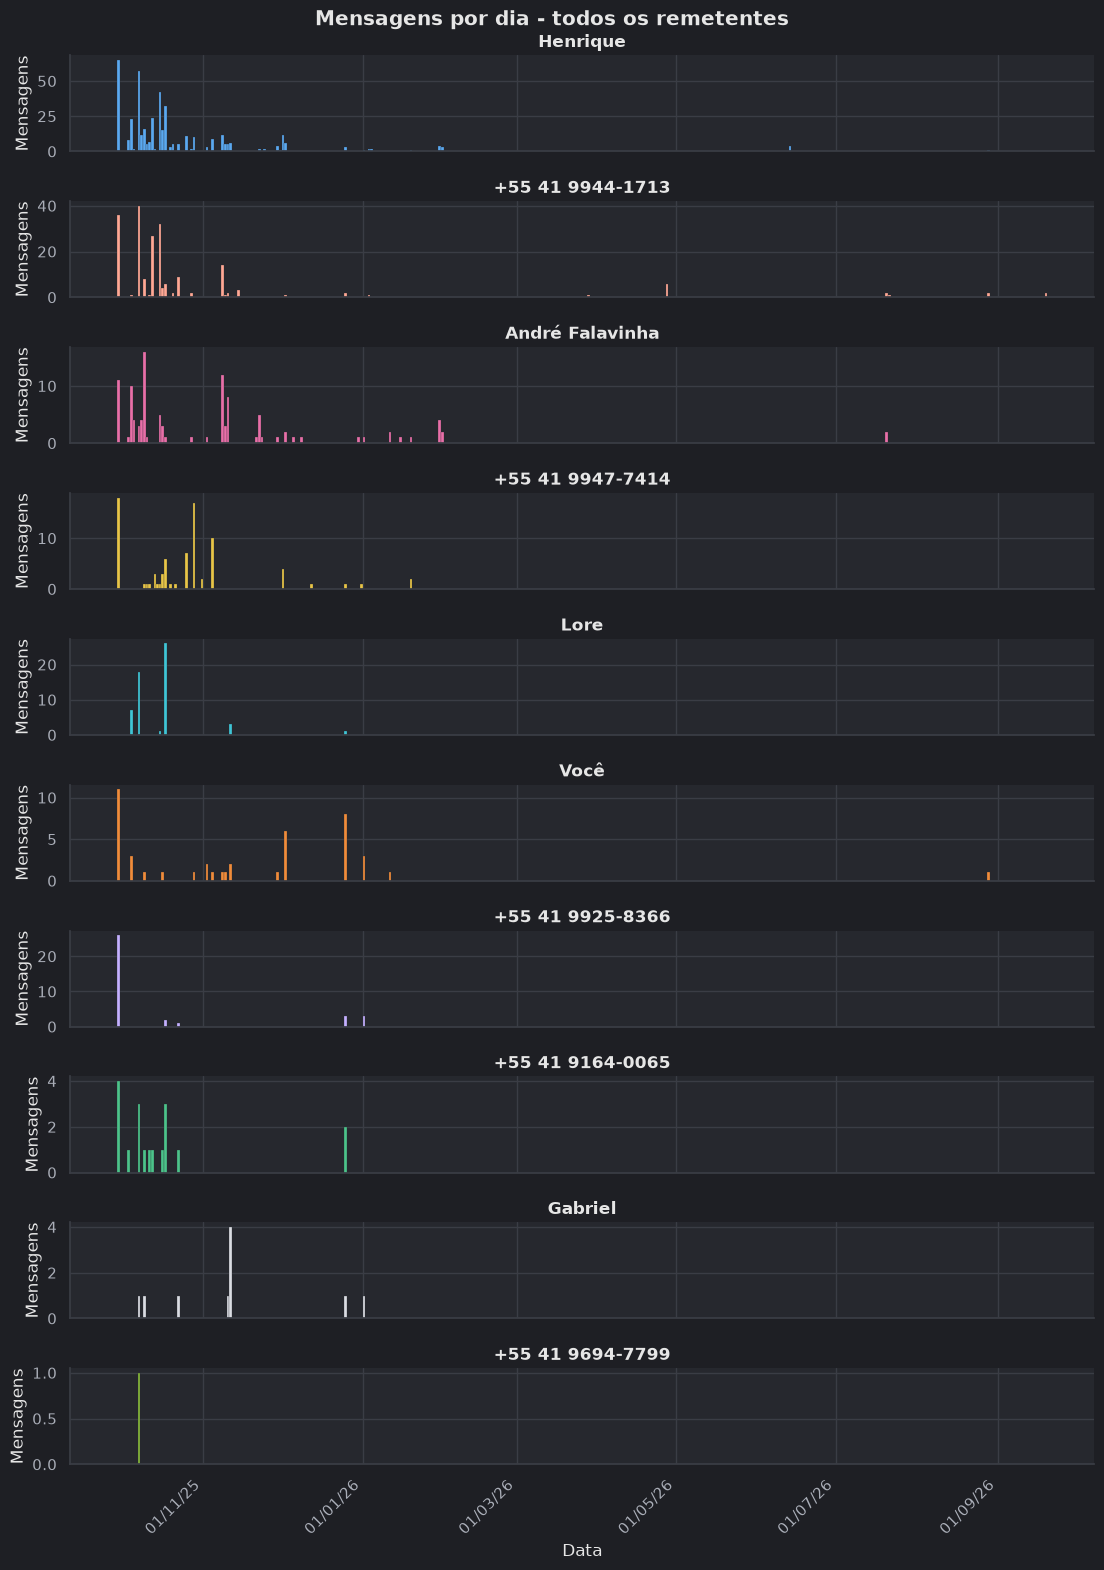

In [7]:
def mostrar_grafico_historico():
    if seletor_grafico.value == "Todos":
        fig = grafico_historico_remetente(df)
    else:
        fig = grafico_historico_remetente(df, seletor_grafico.value)
    saida_grafico_historico.update(fig)
    plt.close(fig)


seletor_grafico = widgets.Dropdown(options=["Todos"] + listar_remetentes(df), description="Remetente:")
seletor_grafico.observe(lambda mudanca: mostrar_grafico_historico(), names="value")
display(seletor_grafico)

fig = grafico_historico_remetente(df)
saida_grafico_historico = display(fig, display_id=True)
plt.close(fig)

---

## 7. Gráfico

Percentual de mensagens de cada remetente. Fatias menores que 3 % não mostram o número dentro da fatia:

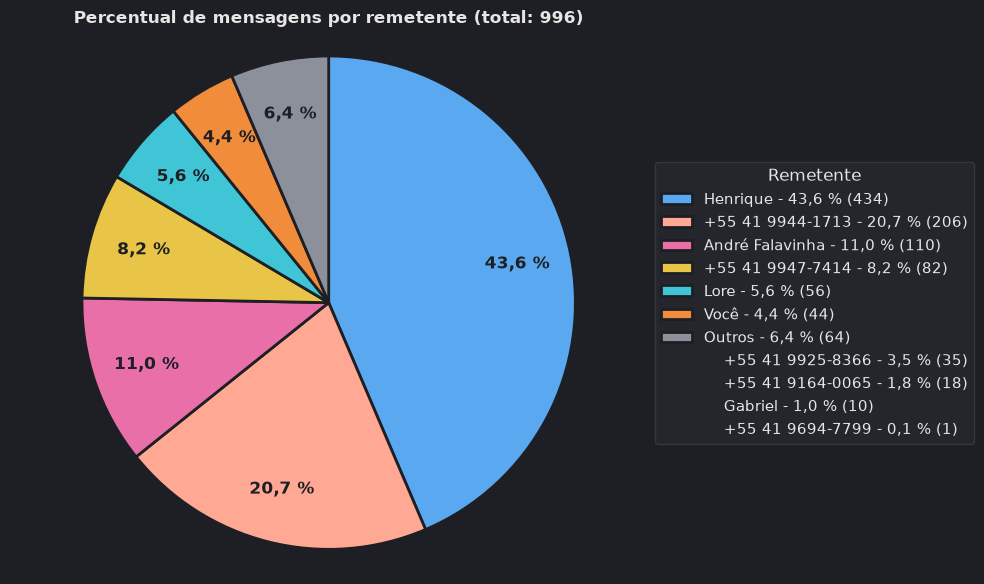

In [8]:
def mostrar_pizza():
    fig = grafico_pizza(df)
    saida_pizza.update(fig)
    plt.close(fig)


fig = grafico_pizza(df)
saida_pizza = display(fig, display_id=True)
plt.close(fig)

---

## 8. Gráfico de linhas

Mensagens ao longo do tempo, todos os remetentes no mesmo gráfico, uma cor por remetente. Escolha o agrupamento: por **dia** (padrão), por **semana** ou por **mês**, mais legível numa conversa longa.

Dropdown(description='Agrupar por:', options=(('Dia', 'D'), ('Semana', 'W'), ('Mês', 'MS')), value='D')

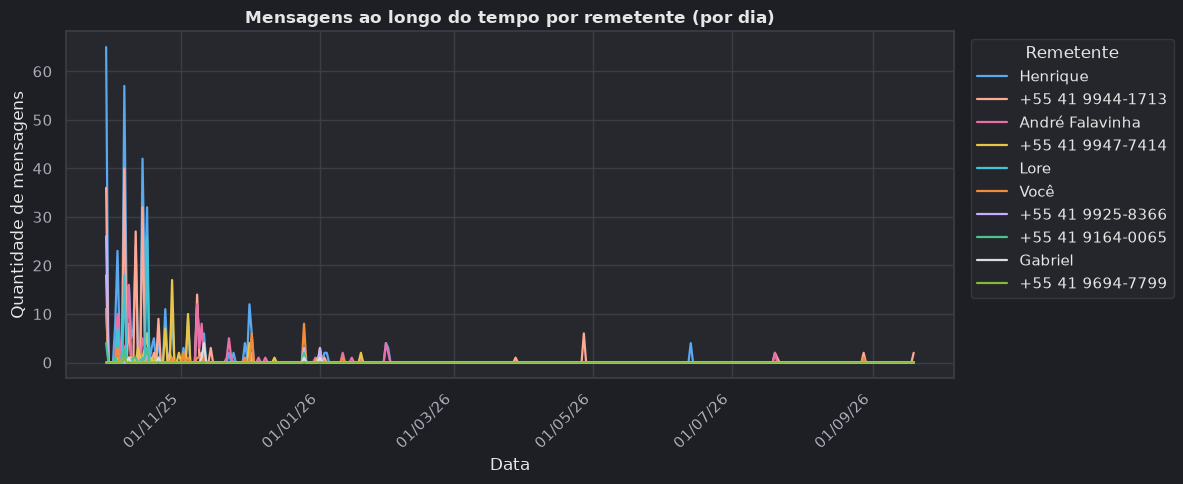

In [9]:
def mostrar_linhas():
    fig = grafico_linhas(df, freq=seletor_periodo.value)
    saida_linhas.update(fig)
    plt.close(fig)


seletor_periodo = widgets.Dropdown(
    options=[("Dia", "D"), ("Semana", "W"), ("Mês", "MS")],
    description="Agrupar por:",
)
seletor_periodo.observe(lambda mudanca: mostrar_linhas(), names="value")
display(seletor_periodo)

fig = grafico_linhas(df, freq=seletor_periodo.value)
saida_linhas = display(fig, display_id=True)
plt.close(fig)

---

# Conclusões

Consideramos algo como uma aplicação web para o desenvolvimento do projeto, mas consideramos que um notebook estaria mais próximo do assunto das aulas anteriores 
e portanto escolhemos utilizar o jupyter lab ao invés de algo como FastAPI